# H-GradCAM: Validation Explainability for H3 Deep Feature Fusion

**Project:** Stain-Robust Explainable Deep Feature Fusion Framework for Lung Cancer Histopathology Subtype Classification  
**Frozen selected model:** `H3_MobileNetV2_EfficientNetB0_fusion_seed42` (source runs H1 and H2)  
**Purpose:** Generate paired, branch-specific Grad-CAM visualizations for reproducibly chosen **validation** examples. No model fitting, resplitting, stain transformation, or held-out test evaluation is performed.

H3 concatenates the 1,280-dimensional MobileNetV2 and EfficientNetB0 pooled features (2,560 total) and applies its **trained fusion head**. The two Grad-CAM branches will both differentiate the **same predicted-class logit of the complete H3 fused classifier**, not the independent H1/H2 three-class classification heads. Each branch heatmap is normalized separately; its color intensity **cannot** be used to compare the branch contributions quantitatively.

The saved H3 image model expects original RGB images as float32 pixels in **[0, 255]**, resized to 224 × 224 with padding and bilinear antialiasing. MobileNetV2's [-1, 1] scaling is stored in the H1 feature extractor and EfficientNetB0 has its own built-in preprocessing. **Do not apply Reinhard normalization or extra input scaling to this selected H3 pipeline.**

Run **one section at a time** and check its output. Do not use *Run all*. This notebook reads only the fixed manifest, previously saved artifacts, and six selected validation images. The original H1/H2/H3 checkpoints, the model-selection freeze, and the data manifests are read-only. Its output directory is separate from all training, stain, and ultrasound runs.

**Interpretation boundary:** These are coarse attribution illustrations, not ground-truth tumor localization, causal proof, independent-hospital validation, or medical diagnosis. Reconstructed source-image groups are **not** patient/slide/institution identifiers. Check data and image reuse permissions before public publication.

## Section 1: Verify the frozen H3 selection and reference checkpoints

Read the saved model-selection freeze and verify the full H3 image model, H3 head, original H1/H2 source checkpoints, configuration, fixed manifest, and class mapping. SHA-256 checks must match historical records. Do not execute training cells from H1, H2, H3, or H4.

In [1]:
from pathlib import Path, PurePosixPath
import hashlib
import json
import platform

import tensorflow as tf
from tensorflow import keras
from google.colab import drive

ROOT = Path('/content/drive/MyDrive/ICTIU_Final_Projects')
if not ROOT.is_dir():
    drive.mount('/content/drive')
if not ROOT.is_dir():
    raise FileNotFoundError('Project Drive root is unavailable.')

PROJECT = ROOT / 'lung'
H1_RUN = PROJECT / 'results/H1_MobileNetV2_frozen_seed42'
H2_RUN = PROJECT / 'results/H2_EfficientNetB0_frozen_seed42'
H3_RUN = PROJECT / 'results/H3_MobileNetV2_EfficientNetB0_fusion_seed42'
H1_MODEL = H1_RUN / 'best_model.keras'
H2_MODEL = H2_RUN / 'best_model.keras'
H3_MODEL = H3_RUN / 'fusion_image_model.keras'
H3_HEAD = H3_RUN / 'best_head.keras'
H3_CONFIG = H3_RUN / 'configuration.json'
H3_PREDICTIONS = H3_RUN / 'validation_predictions.csv'
MANIFEST_PATH = PROJECT / 'splits/manifest_candidate.csv'
MAPPING_PATH = PROJECT / 'splits/class_mapping.json'
ZIP_PATH = PROJECT / 'archives/LC25000.zip'
FREEZE_PATH = PROJECT / 'selection/H3_model_selection_freeze_2026-10-19.json'

EXPECTED_SHA256 = {
    'h1_model': '503559b9333124d8be0b665a9fd9538220a750db2274ca55a9e61dff503dd6bf',
    'h2_model': 'fcd95f3198c1a63641462b3a72e6b21cf501a4ad0928186bd91c2362c53fa5f6',
    'h3_model': '9e1a5bbf49da7e88a529f5ac08303c65e138d7c9f818959aaddd46f609890c95',
    'h3_head': '77deea98faef81db0fd8e6574598f677a18f9368fde3edccc67c3549b5098b75',
    'h3_config': 'efac45117571f4223de67c62dfcfd4751ba52122d972885d19222782cf9f386c',
    'manifest': 'd931c9b11d03716c3c426f251bc75eaa2051002acca99d3ba66d59d964285dea',
    'mapping': '4d14782118e3a438c13b209d7a594f2f9676d09cec25125b599d8c6d6c26a6a8',
}

CHECK_FILES = {
    'h1_model': H1_MODEL, 'h2_model': H2_MODEL,
    'h3_model': H3_MODEL, 'h3_head': H3_HEAD, 'h3_config': H3_CONFIG,
    'manifest': MANIFEST_PATH, 'mapping': MAPPING_PATH,
}

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(4 * 1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

required = list(CHECK_FILES.values()) + [FREEZE_PATH, ZIP_PATH, H3_PREDICTIONS]
missing = [str(p) for p in required if not p.is_file() or p.stat().st_size == 0]
if missing:
    raise FileNotFoundError('Missing saved experiment evidence: ' + str(missing))
for key, path in CHECK_FILES.items():
    actual = sha256_file(path)
    if actual != EXPECTED_SHA256[key]:
        raise RuntimeError(f'Frozen artifact SHA-256 mismatch: {key} ({path})')

freeze = json.loads(FREEZE_PATH.read_text(encoding='utf-8'))
assert freeze['selected_experiment'] == 'H3_MobileNetV2_EfficientNetB0_fusion_seed42'
assert freeze['decision_status'] == 'FROZEN_BEFORE_HELD_OUT_TEST'
for key, path in [
    ('model_artifact', H3_MODEL), ('head_artifact', H3_HEAD),
    ('configuration', H3_CONFIG), ('manifest', MANIFEST_PATH),
    ('mapping_file', MAPPING_PATH),
]:
    entry = freeze[key]
    assert ROOT / entry['path_relative_to_root'] == path, key
    assert sha256_file(path) == entry['sha256'], key

config = json.loads(H3_CONFIG.read_text(encoding='utf-8'))
assert config['source_sha256']['manifest'] == EXPECTED_SHA256['manifest']
assert config['backbones_frozen'] is True
assert config['feature_extraction'].startswith('global_average_pooling')
assert config['class_to_id'] == freeze['class_to_id']

print('Python:', platform.python_version())
print('TensorFlow:', tf.__version__)
print('GPU devices:', tf.config.list_physical_devices('GPU'))
print('Frozen H3 image-model SHA-256:', EXPECTED_SHA256['h3_model'])
print('Frozen H3 head SHA-256:', EXPECTED_SHA256['h3_head'])
print('H1/H2 reference checkpoints: verified')
print('Selection record:', FREEZE_PATH.name)
print('SECTION 1 PASS: H3 selection and all source artifacts verified; no test images read.')

Mounted at /content/drive
Python: 3.13.15
TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Frozen H3 image-model SHA-256: 9e1a5bbf49da7e88a529f5ac08303c65e138d7c9f818959aaddd46f609890c95
Frozen H3 head SHA-256: 77deea98faef81db0fd8e6574598f677a18f9368fde3edccc67c3549b5098b75
H1/H2 reference checkpoints: verified
Selection record: H3_model_selection_freeze_2026-10-19.json
SECTION 1 PASS: H3 selection and all source artifacts verified; no test images read.


## Section 2: Audit the original manifest and select fixed validation cases

Inspect the immutable 15,000-row manifest **metadata**. Confirm reconstructed source-image-group separation and all class IDs. Select **two validation images per class** using a stable SHA-256 ranking and six distinct reconstructed source-image groups. Selection happens **before model predictions** and does not depend on whether the model is right or on how appealing a heatmap looks. These groups are not patient IDs.

In [2]:
import pandas as pd

EXPECTED_CLASSES = {'lung_aca': 0, 'lung_n': 1, 'lung_scc': 2}
class_to_id = json.loads(MAPPING_PATH.read_text(encoding='utf-8'))
assert class_to_id == EXPECTED_CLASSES
assert freeze['class_to_id'] == EXPECTED_CLASSES
CLASS_NAMES = [name for name, _ in sorted(class_to_id.items(), key=lambda t: t[1])]

raw = pd.read_csv(MANIFEST_PATH, dtype=str, keep_default_na=False)

def find_column(names, required=True):
    lookup = {str(col).lower().strip(): col for col in raw.columns}
    name = next((lookup[alias] for alias in names if alias in lookup), None)
    if required and name is None:
        raise ValueError(f'Cannot locate a required manifest field: {names}')
    return name

path_col = find_column(['relative_path', 'rel_path', 'relpath', 'image_path',
                        'filepath', 'file_path', 'path', 'filename', 'image_name'])
split_col = find_column(['split', 'subset', 'partition'])
group_col = find_column(['group_id', 'source_group_id', 'source_group',
                         'source_image_group', 'original_group', 'source_image_id'])
name_col = find_column(['class_name', 'category', 'class', 'label_name'], required=False)
id_col = find_column(['class_id', 'label_id', 'label_idx'], required=False)
hash_col = find_column(['sha256', 'file_sha256', 'image_sha256', 'sha256_hash'], required=False)
if name_col is None and id_col is None:
    raise ValueError('No class name or ID column in the fixed manifest.')

split_alias = {'train': 'train', 'training': 'train', 'val': 'val',
               'valid': 'val', 'validation': 'val', 'test': 'test', 'testing': 'test'}
split = raw[split_col].str.strip().str.lower().map(split_alias)
if split.isna().any():
    raise ValueError('Unexpected split assignment in original manifest.')

if name_col is not None:
    names = raw[name_col].str.strip()
    if not names.isin(EXPECTED_CLASSES).all():
        raise ValueError('Unexpected lung class name.')
    cid = names.map(class_to_id).astype(int)
else:
    cid = raw[id_col].astype(int)
    names = cid.map({v: k for k, v in class_to_id.items()})
if id_col is not None and not (raw[id_col].astype(int) == cid).all():
    raise ValueError('Class names and class IDs disagree.')

manifest = pd.DataFrame({
    'source_path': raw[path_col].str.strip(),
    'split': split, 'source_group': raw[group_col].str.strip(),
    'class_id': cid, 'class_name': names,
})
if hash_col:
    manifest['recorded_sha256'] = raw[hash_col].str.strip().str.lower()
    assert manifest['recorded_sha256'].str.fullmatch(r'[0-9a-f]{64}').all()
if manifest[['source_path', 'source_group']].eq('').any().any():
    raise ValueError('Blank paths or grouping IDs.')
assert len(manifest) == 15000
assert manifest['source_path'].is_unique
assert manifest['split'].value_counts().to_dict() == {
    'train': 10394, 'val': 2273, 'test': 2333,
}
assert manifest.groupby('split')['source_group'].nunique().to_dict() == {
    'train': 514, 'val': 113, 'test': 113,
}
assert manifest['source_group'].nunique() == 740
assert not (manifest.groupby('source_group')['split'].nunique() > 1).any()
assert not (manifest.groupby('source_group')['class_id'].nunique() > 1).any()
assert manifest['class_name'].value_counts().to_dict() == {k: 5000 for k in EXPECTED_CLASSES}
if hash_col:
    assert not (manifest.groupby('recorded_sha256')['split'].nunique() > 1).any()

val = manifest[manifest['split'] == 'val'].copy()
assert val['class_id'].value_counts().sort_index().to_dict() == {0: 758, 1: 764, 2: 751}
SELECTION_SEED = 'H3_gradcam_validation_seed42_v1'
val['_rank'] = val['source_path'].map(
    lambda p: hashlib.sha256((SELECTION_SEED + '|' + p).encode()).hexdigest()
)
val = val.sort_values(['class_id', '_rank', 'source_path'])
selected = []
used_groups = set()
for idx in range(3):
    count = 0
    for _, row in val[val.class_id == idx].iterrows():
        if row['source_group'] in used_groups:
            continue
        used_groups.add(row['source_group'])
        item = row.drop(labels=['_rank']).to_dict()
        item['selection_hash'] = row['_rank']
        selected.append(item)
        count += 1
        if count == 2:
            break
    if count != 2:
        raise RuntimeError(f'Could not select two separate validation groups for class {idx}.')
cases = pd.DataFrame(selected).reset_index(drop=True)
assert len(cases) == 6
assert cases['source_path'].is_unique
assert cases['source_group'].nunique() == 6
assert set(cases['split']) == {'val'}

print('Selected validation examples:', len(cases))
print('Distinct reconstructed source-image groups:', cases['source_group'].nunique())
print(cases.groupby('class_name', sort=False).size().to_string())
print('SECTION 2 PASS: Deterministic selection fixed before model inference.')

Selected validation examples: 6
Distinct reconstructed source-image groups: 6
class_name
lung_aca    2
lung_n      2
lung_scc    2
SECTION 2 PASS: Deterministic selection fixed before model inference.


## Section 3: Restore the six selected validation images from the saved LC25000 ZIP

Resolve each selected manifest record to a **unique matching ZIP member** by original class and basename, following the H3 archive policy. Extract only these six validation images into disposable Colab storage; do **not** re-download LC25000 or extract training/test images. Validate archive CRC and any recorded image SHA-256. Existing temporary copies may be reused only after checking their integrity.

In [3]:
import stat
import zipfile
import zlib
from collections import defaultdict

WORK = Path('/content/ictiu_data/lung_h3_gradcam')
WORK.mkdir(parents=True, exist_ok=True)

def crc32_bytes(data):
    return zlib.crc32(data) & 0xffffffff

image_paths = []
with zipfile.ZipFile(ZIP_PATH, 'r') as archive:
    by_file = defaultdict(list)
    for info in archive.infolist():
        member = PurePosixPath(info.filename.replace('\\', '/'))
        if info.is_dir() or '__MACOSX' in member.parts or member.name.startswith('._'):
            continue
        if member.suffix.lower() not in {'.png', '.jpg', '.jpeg'}:
            continue
        matching_class_parts = [part for part in member.parts if part in EXPECTED_CLASSES]
        if len(matching_class_parts) == 1:
            by_file[(matching_class_parts[0], member.name)].append(info)

    matched = []
    for row in cases.itertuples(index=False):
        basename = PurePosixPath(str(row.source_path).replace('\\', '/')).name
        candidates = by_file.get((row.class_name, basename), [])
        if len(candidates) != 1:
            raise RuntimeError(f'Expected a unique ZIP member for {row.class_name}/{basename}, got {len(candidates)}.')
        info = candidates[0]
        member = PurePosixPath(info.filename.replace('\\', '/'))
        if (member.is_absolute() or '..' in member.parts or
            stat.S_ISLNK(info.external_attr >> 16)):
            raise RuntimeError(f'Unsafe archive member: {info.filename}')
        if info.file_size <= 0 or info.file_size > 30 * 1024**2:
            raise RuntimeError(f'Unexpected archive image size: {info.filename}')
        matched.append(info.filename)
        target = WORK / row.class_name / basename
        target.parent.mkdir(parents=True, exist_ok=True)
        if not target.resolve().is_relative_to(WORK.resolve()):
            raise RuntimeError('Unsafe local image path.')
        with archive.open(info, 'r') as source:
            data = source.read()
        if len(data) != info.file_size or crc32_bytes(data) != info.CRC:
            raise IOError(f'ZIP CRC mismatch for {info.filename}')
        if 'recorded_sha256' in cases.columns:
            actual = hashlib.sha256(data).hexdigest()
            if actual != row.recorded_sha256:
                raise IOError(f'Image SHA-256 differs from the original manifest: {info.filename}')
        if target.is_file():
            if target.read_bytes() != data:
                raise RuntimeError(f'An existing temporary image differs from the verified ZIP: {target}')
        else:
            temp = target.with_name(target.name + '.partial')
            with temp.open('xb') as out:
                out.write(data)
            temp.replace(target)
        image_paths.append(target)

assert len(image_paths) == 6 and len(set(matched)) == 6
print('Verified / restored validation images:', len(image_paths))
print('Saved ZIP:', ZIP_PATH.name)
print('Per-image manifest SHA-256 available:', 'recorded_sha256' in cases.columns)
print('SECTION 3 PASS: Only selected validation pixels restored; test pixels untouched.')

Verified / restored validation images: 6
Saved ZIP: LC25000.zip
Per-image manifest SHA-256 available: True
SECTION 3 PASS: Only selected validation pixels restored; test pixels untouched.


## Section 4: Load H3 and reconstruct **the same fused inference** from H1/H2

Load the frozen H1/H2 feature extractors and the **original trained H3 fusion head**, not the H1/H2 classification heads. Reproduce H3 image preprocessing (`tf.image.resize_with_pad`, bilinear, antialias). Compare all six reconstructed head predictions with the exported H3 full-image model, and check their predicted IDs against `validation_predictions.csv` saved by H3. A disagreement is a blocker; do not produce a Grad-CAM based on an unverified alternative prediction path.

In [4]:
import numpy as np

keras.utils.set_random_seed(42)
keras.mixed_precision.set_global_policy('float32')
IMG_SIZE = (224, 224)

h1_saved = keras.models.load_model(str(H1_MODEL), compile=False)
h2_saved = keras.models.load_model(str(H2_MODEL), compile=False)
h3_head = keras.models.load_model(str(H3_HEAD), compile=False)
h3_full = keras.models.load_model(str(H3_MODEL), compile=False)

h1_rescale = h1_saved.get_layer('mobilenetv2_rescaling')
h1_backbone = h1_saved.get_layer('mobilenetv2_1.00_224')
h2_backbone = h2_saved.get_layer('efficientnetb0')
h3_dense = h3_head.get_layer('fusion_class_scores')
assert isinstance(h1_rescale, keras.layers.Rescaling)
assert abs(float(h1_rescale.scale) - 1 / 127.5) < 1e-8
assert abs(float(h1_rescale.offset) + 1) < 1e-8
assert any(isinstance(x, keras.layers.Rescaling) for x in h2_backbone.layers)
assert h1_backbone.trainable is False and h2_backbone.trainable is False
assert h1_backbone.layers[-1].name == 'out_relu'
assert h2_backbone.layers[-1].name == 'top_activation'
assert tuple(h3_dense.kernel.shape) == (2560, 3)
assert h3_dense.activation.__name__ == 'softmax'
assert len(h3_head.layers) == 3  # input, dropout, softmax dense
assert tuple(h3_full.input_shape[1:]) == (224, 224, 3)

h1_extractor = keras.Model(h1_saved.inputs,
    h1_saved.get_layer('global_average_pooling').output, name='H1_saved_pooled_features')
h2_extractor = keras.Model(h2_saved.inputs,
    h2_saved.get_layer('global_average_pooling').output, name='H2_saved_pooled_features')
h1_extractor.trainable = False
h2_extractor.trainable = False
assert tuple(h1_extractor.output_shape[1:]) == (1280,)
assert tuple(h2_extractor.output_shape[1:]) == (1280,)

def read_image(path):
    contents = tf.io.read_file(str(path))
    decoded = tf.io.decode_image(contents, channels=3, expand_animations=False)
    decoded.set_shape([None, None, 3])
    pixels = tf.cast(decoded, tf.float32)
    pixels = tf.image.resize_with_pad(
        pixels, 224, 224, method='bilinear', antialias=True)
    return tf.ensure_shape(pixels, (224, 224, 3))

images = tf.stack([read_image(path) for path in image_paths], axis=0)
assert tuple(images.shape) == (6, 224, 224, 3)
assert np.isfinite(images.numpy()).all()
assert 0.0 <= float(tf.reduce_min(images)) <= float(tf.reduce_max(images)) <= 255.0

feat1 = h1_extractor(images, training=False).numpy()
feat2 = h2_extractor(images, training=False).numpy()
fused_features = np.concatenate([feat1, feat2], axis=-1)
assert fused_features.shape == (6, 2560)
head_scores = h3_head(fused_features, training=False).numpy()
full_scores = h3_full(images, training=False).numpy()
np.testing.assert_allclose(full_scores, head_scores, rtol=2e-4, atol=2e-4)
assert np.isfinite(full_scores).all()
assert np.allclose(full_scores.sum(axis=1), 1, atol=2e-5)
pred_ids = np.argmax(full_scores, axis=1)

historical = pd.read_csv(H3_PREDICTIONS).set_index('source_path', verify_integrity=True)
for i, row in cases.iterrows():
    if row['source_path'] not in historical.index:
        raise RuntimeError('Selected validation image missing from H3 history: ' + row['source_path'])
    previous = int(historical.at[row['source_path'], 'predicted_id'])
    if previous != int(pred_ids[i]):
        raise RuntimeError('Historical H3 prediction differs for ' + row['source_path'])

print('Image input shape:', images.shape)
print('Source feature shapes:', feat1.shape, feat2.shape)
print('H3 fused feature shape:', fused_features.shape)
print('Full-model vs fused-head max difference:',
      float(np.max(np.abs(full_scores - head_scores))))
print('Historical H3 prediction agreement: 6/6')
print('SECTION 4 PASS: Original H3 inference and preprocessing reproduced.')

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 6 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Image input shape: (6, 224, 224, 3)
Source feature shapes: (6, 1280) (6, 1280)
H3 fused feature shape: (6, 2560)
Full-model vs fused-head max difference: 0.0
Historical H3 prediction agreement: 6/6
SECTION 4 PASS: Original H3 inference and preprocessing reproduced.


## Section 5: Verify branch-specific gradients to the **H3 predicted-class logit**

Take `out_relu` (MobileNetV2, 7 × 7) and `top_activation` (EfficientNetB0, 7 × 7) as spatial feature maps. Pool and concatenate their outputs exactly as H3 does. Reconstruct **pre-softmax H3 fusion logits from the saved H3 Dense weights**, then differentiate the **same winning fused logit** with respect to each branch's feature map. Verify probabilities against the saved full H3 model; gradients must be finite. A ReLU Grad-CAM may legitimately be all-zero, which will be recorded rather than hidden.

In [5]:
cam_h1 = keras.Model(
    inputs=h1_backbone.input, outputs=h1_backbone.get_layer('out_relu').output,
    name='H3_MobileNetV2_last_spatial')
cam_h2 = keras.Model(
    inputs=h2_backbone.input, outputs=h2_backbone.get_layer('top_activation').output,
    name='H3_EfficientNetB0_last_spatial')
assert tuple(cam_h1.output.shape[1:]) == (7, 7, 1280)
assert tuple(cam_h2.output.shape[1:]) == (7, 7, 1280)


def branch_gradcam(image):
    batch = tf.convert_to_tensor(image, dtype=tf.float32)[None, ...]
    with tf.GradientTape() as tape:
        # EfficientNetB0's own preprocessing is inside its backbone.
        h1_maps = cam_h1(h1_rescale(batch, training=False), training=False)
        h2_maps = cam_h2(batch, training=False)
        tape.watch([h1_maps, h2_maps])
        pooled_h1 = tf.reduce_mean(h1_maps, axis=(1, 2))
        pooled_h2 = tf.reduce_mean(h2_maps, axis=(1, 2))
        vec = tf.concat([pooled_h1, pooled_h2], axis=-1)
        logits = tf.linalg.matmul(vec, h3_dense.kernel)
        if h3_dense.use_bias:
            logits = tf.nn.bias_add(logits, h3_dense.bias)
        winner = int(tf.argmax(logits[0]).numpy())
        logit_target = logits[0, winner]

    gradients = tape.gradient(logit_target, [h1_maps, h2_maps])
    if any(g is None for g in gradients):
        raise RuntimeError('Missing gradient to one or both frozen backbone feature maps.')

    reconstructed = tf.nn.softmax(logits, axis=-1).numpy()
    original = h3_full(batch, training=False).numpy()
    mismatch = float(np.max(np.abs(reconstructed - original)))
    if mismatch > 2e-4:
        raise RuntimeError(f'Grad-CAM fusion inference differs from frozen H3: {mismatch:.6g}')

    def weighted_cam(feature_map, grad):
        if not bool(tf.reduce_all(tf.math.is_finite(grad))):
            raise RuntimeError('Non-finite gradient detected.')
        weights = tf.reduce_mean(grad, axis=(1, 2), keepdims=True)
        raw = tf.nn.relu(tf.reduce_sum(weights * feature_map, axis=-1))
        peak = float(tf.reduce_max(raw).numpy())
        normalized = raw / (tf.reduce_max(raw) + 1e-8)
        pixels = tf.image.resize(normalized[..., None], IMG_SIZE,
                                 method='bilinear')[0, :, :, 0]
        pixels = tf.clip_by_value(pixels, 0, 1).numpy()
        if not np.isfinite(pixels).all():
            raise RuntimeError('Non-finite branch Grad-CAM values.')
        return {
            'map': pixels,
            'raw_peak': peak,
            'gradient_l1': float(tf.reduce_sum(tf.abs(grad)).numpy()),
        }

    return {
        'predicted_id': winner,
        'softmax_score_uncalibrated': float(reconstructed[0, winner]),
        'probability_max_difference': mismatch,
        'mobilenetv2': weighted_cam(h1_maps, gradients[0]),
        'efficientnetb0': weighted_cam(h2_maps, gradients[1]),
    }

smoke = branch_gradcam(images[0])
assert smoke['predicted_id'] == int(pred_ids[0])
print('Attribution target: H3 fused predicted-class logit')
print('MobileNetV2 spatial layer: out_relu (7x7)')
print('EfficientNetB0 spatial layer: top_activation (7x7)')
print('Reconstructed vs frozen H3 maximum difference:',
      f"{smoke['probability_max_difference']:.7g}")
for branch in ('mobilenetv2', 'efficientnetb0'):
    stats = smoke[branch]
    print(branch, '| gradient L1:', f"{stats['gradient_l1']:.7g}",
          '| raw Grad-CAM peak:', f"{stats['raw_peak']:.7g}")
    if stats['raw_peak'] <= 0:
        print('NOTE:', branch, 'has a zero ReLU CAM for this example; preserve this result.')
print('SECTION 5 PASS: Both branch gradients trace to the SAME saved H3 fused decision.')

Attribution target: H3 fused predicted-class logit
MobileNetV2 spatial layer: out_relu (7x7)
EfficientNetB0 spatial layer: top_activation (7x7)
Reconstructed vs frozen H3 maximum difference: 0
mobilenetv2 | gradient L1: 70.01093 | raw Grad-CAM peak: 0.1797625
efficientnetb0 | gradient L1: 74.32286 | raw Grad-CAM peak: 0.3131664
SECTION 5 PASS: Both branch gradients trace to the SAME saved H3 fused decision.


## Section 6: Visually inspect paired H3 explanations on the first validation image

Preview the original 224 × 224 padded RGB image, separate branch heatmaps, and separate overlays. These maps are **individually normalized** to [0, 1]; equivalent colors across panels are not evidence that the branches contributed equally to the fused logit. Observe possible attention to image edges, black padding, or staining artifacts. Do not reselect examples or change the frozen model based on heatmap appearance.

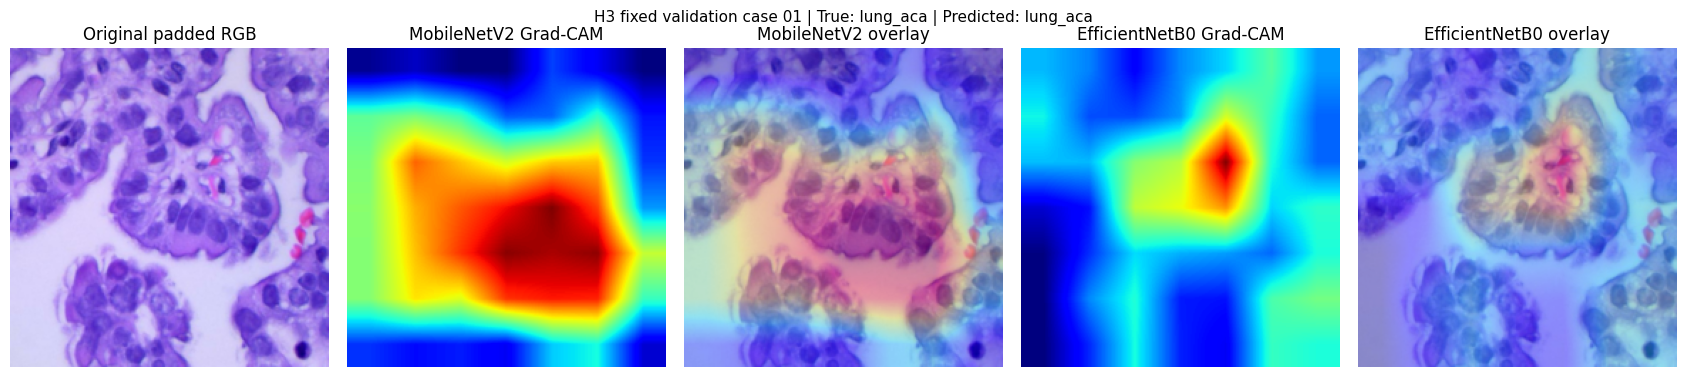

SECTION 6 PASS: First dual-branch validation explanation previewed (not exported).


In [6]:
import matplotlib.pyplot as plt


def make_panel(image, result, true_class, case_number):
    original = np.clip(np.asarray(image), 0, 255).astype(np.uint8)
    pred_name = CLASS_NAMES[result['predicted_id']]
    fig, axes = plt.subplots(1, 5, figsize=(17, 3.8))
    axes[0].imshow(original)
    axes[0].set_title('Original padded RGB')
    for branch, heat_ax, overlay_ax, label in [
        ('mobilenetv2', axes[1], axes[2], 'MobileNetV2'),
        ('efficientnetb0', axes[3], axes[4], 'EfficientNetB0'),
    ]:
        heat = result[branch]['map']
        heat_ax.imshow(heat, cmap='jet', vmin=0, vmax=1)
        heat_ax.set_title(label + ' Grad-CAM')
        overlay_ax.imshow(original)
        overlay_ax.imshow(heat, cmap='jet', alpha=0.35, vmin=0, vmax=1)
        overlay_ax.set_title(label + ' overlay')
    for ax in axes:
        ax.axis('off')
    fig.suptitle(
        f'H3 fixed validation case {case_number:02d} | True: {true_class} | Predicted: {pred_name}',
        fontsize=11)
    fig.tight_layout()
    return fig

preview = make_panel(images[0].numpy(), smoke, cases.iloc[0]['class_name'], 1)
plt.show()
plt.close(preview)
print('SECTION 6 PASS: First dual-branch validation explanation previewed (not exported).')

## Section 7: Export reproducible **validation-only** H3 Grad-CAM evidence

Save all six cases, an overview with both branches for one preselected case from each class, a descriptive CSV, provenance, notes for the report, and SHA-256 checksums. Output goes to `lung/results/H_GradCAM_H3_validation_seed42/` and cannot overwrite any previous H1/H2/H3/H4 or Grad-CAM outputs. Staging under `/content` prevents partially generated visuals from becoming an apparently completed evidence directory. Case selection is not modified by prediction accuracy or heatmap shape.

In [7]:
import shutil
from datetime import datetime, timezone

RUN_NAME = 'H_GradCAM_H3_validation_seed42'
OUT_DIR = PROJECT / 'results' / RUN_NAME
STAGE = Path('/content') / (RUN_NAME + '_staging')
if OUT_DIR.exists():
    raise FileExistsError(f'Existing Grad-CAM results will not be overwritten: {OUT_DIR}')
if STAGE.exists():
    raise FileExistsError(f'Staging directory already exists; inspect it: {STAGE}')
STAGE.mkdir(parents=True, exist_ok=False)
(STAGE / 'panels').mkdir()

records = []
results = []
for i, row in cases.iterrows():
    result = branch_gradcam(images[i])
    if result['predicted_id'] != int(pred_ids[i]):
        raise RuntimeError('Grad-CAM classification does not match frozen H3.')
    panel_file = STAGE / 'panels' / f'validation_{i + 1:02d}_branches.png'
    fig = make_panel(images[i].numpy(), result, row['class_name'], i + 1)
    fig.savefig(panel_file, dpi=155, bbox_inches='tight')
    plt.close(fig)
    records.append({
        'case_number': i + 1,
        'partition': 'validation',
        'source_path': row['source_path'],
        'selection_hash': row['selection_hash'],
        'true_id': int(row['class_id']),
        'true_class': row['class_name'],
        'predicted_id': result['predicted_id'],
        'predicted_class': CLASS_NAMES[result['predicted_id']],
        'correct': bool(result['predicted_id'] == int(row['class_id'])),
        'softmax_score_uncalibrated': result['softmax_score_uncalibrated'],
        'reconstructed_vs_frozen_h3_max_abs_diff': result['probability_max_difference'],
        'mobilenetv2_raw_cam_peak': result['mobilenetv2']['raw_peak'],
        'mobilenetv2_gradient_l1': result['mobilenetv2']['gradient_l1'],
        'efficientnetb0_raw_cam_peak': result['efficientnetb0']['raw_peak'],
        'efficientnetb0_gradient_l1': result['efficientnetb0']['gradient_l1'],
        'panel_path': str(panel_file.relative_to(STAGE)),
    })
    results.append(result)

table = pd.DataFrame(records)
assert len(table) == 6 and set(table['partition']) == {'validation'}
table.to_csv(STAGE / 'validation_gradcam_examples.csv', index=False)

fig, axes = plt.subplots(3, 2, figsize=(8.5, 12))
for cid in range(3):
    j = int(table.index[table['true_id'] == cid][0])
    original = np.clip(images[j].numpy(), 0, 255).astype(np.uint8)
    for column, (branch, title) in enumerate([
        ('mobilenetv2', 'MobileNetV2 branch'),
        ('efficientnetb0', 'EfficientNetB0 branch'),
    ]):
        ax = axes[cid, column]
        ax.imshow(original)
        ax.imshow(results[j][branch]['map'], cmap='jet', vmin=0, vmax=1, alpha=0.35)
        ax.axis('off')
        ax.set_title(f'True: {CLASS_NAMES[cid]} | {title}\n'
                     f'Predicted: {table.loc[j, "predicted_class"]}', fontsize=9)
fig.suptitle('H3 predicted-class Grad-CAM | fixed validation examples', fontsize=11)
fig.tight_layout()
fig.savefig(STAGE / 'gradcam_branch_overview_validation.png', dpi=170, bbox_inches='tight')
plt.close(fig)

selection_records = [
    {'source_path': row['source_path'], 'class_id': int(row['class_id']),
     'selection_hash': row['selection_hash']}
    for _, row in cases.iterrows()
]
metadata = {
    'experiment': RUN_NAME,
    'project': 'Stain-Robust Explainable Deep Feature Fusion for Lung Histopathology',
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'partition': 'validation',
    'held_out_test_images_read': False,
    'model_training_performed': False,
    'model_selection_changed': False,
    'selected_experiment': freeze['selected_experiment'],
    'selected_full_model_sha256': sha256_file(H3_MODEL),
    'selected_head_sha256': sha256_file(H3_HEAD),
    'h1_checkpoint_sha256': sha256_file(H1_MODEL),
    'h2_checkpoint_sha256': sha256_file(H2_MODEL),
    'manifest_sha256': sha256_file(MANIFEST_PATH),
    'mapping_sha256': sha256_file(MAPPING_PATH),
    'selection_freeze_file': str(FREEZE_PATH.relative_to(ROOT)),
    'selection_freeze_sha256': sha256_file(FREEZE_PATH),
    'split_unit': 'reconstructed source-image group (NOT patient/slide/hospital)',
    'selection_rule': '2 per class, SHA-256 ranking of fixed seed|source_path; six distinct source-image groups',
    'selection_seed': SELECTION_SEED,
    'examples_selected_before_predictions': True,
    'selected_examples': selection_records,
    'resize': 'tf.image.resize_with_pad, RGB float32 224x224, bilinear antialias=True',
    'mobilenet_preprocessing': 'H1 saved Rescaling inside feature extractor',
    'efficientnet_preprocessing': 'H2 native EfficientNetB0 preprocessing inside backbone',
    'stain_normalization_applied': False,
    'branch_layers': {'mobilenetv2': 'out_relu', 'efficientnetb0': 'top_activation'},
    'attribution_target': 'same predicted-class PRE-SOFTMAX H3 fused-head logit for both branches',
    'cam_method': 'spatial-average gradient weights; channel-weighted sum; ReLU; independent normalization and resize',
    'normalization_caveat': 'Branch heatmap colors are independently normalized and are not comparable contribution magnitudes.',
    'historical_h3_prediction_agreement': '6/6 selected validation examples',
    'tensorflow': tf.__version__,
    'keras': keras.__version__,
    'limitations': 'Illustrative, coarse localization only; not tumor segmentation, causal attribution, external validation, or clinical diagnosis.',
    'public_sharing_note': 'Check LC25000 image reuse rights before including samples in a public repository.',
}
(STAGE / 'gradcam_provenance.json').write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')

report_note = (
    '# Lung H3 Grad-CAM (validation-only)\n\n'
    'Six examples (two per class) were selected by a fixed SHA-256 ranking from the '
    'original source-group-separated validation partition, before model inference. '
    'The frozen MobileNetV2 `out_relu` and EfficientNetB0 `top_activation` maps (both 7x7) '
    'were differentiated separately with respect to the **same predicted-class pre-softmax '
    'logit** in the trained H3 fusion head. Heatmaps were individually normalized and '
    'overlaid on 224x224 padded images. Independent branch colors cannot be used as '
    'quantitative contribution comparisons. Results are descriptive; no test images '
    'were examined and no tuning or model training occurred. The original lung groups '
    'are reconstructed source-image groups, not patient/slide/hospital groups. '
    'Grad-CAM does not establish histological localization correctness or clinical validity.\n\n'
    'The ratio of correct predictions within these deliberately small fixed examples '
    'is **not** the full-validation accuracy or a held-out-test metric.\n'
)
(STAGE / 'gradcam_report_note.md').write_text(report_note, encoding='utf-8')

checksums = {
    str(path.relative_to(STAGE)): sha256_file(path)
    for path in sorted(STAGE.rglob('*')) if path.is_file()
}
(STAGE / 'artifact_checksums.json').write_text(
    json.dumps(checksums, indent=2) + '\n', encoding='utf-8')

shutil.copytree(STAGE, OUT_DIR)
for rel, digest in checksums.items():
    if sha256_file(OUT_DIR / rel) != digest:
        raise RuntimeError('Drive copy checksum mismatch: ' + rel)

print('SAVED:', OUT_DIR)
print('Saved paired Grad-CAM panels:', len(table))
print('Correct among fixed examples (descriptive only):', int(table['correct'].sum()), '/ 6')
print('Max fused-inference difference:',
      float(table['reconstructed_vs_frozen_h3_max_abs_diff'].max()))
for branch in ('mobilenetv2', 'efficientnetb0'):
    zero_cases = int((table[f'{branch}_raw_cam_peak'] <= 0).sum())
    print(branch, 'zero Grad-CAM cases:', zero_cases)
print('SECTION 7 PASS: Paired validation-only evidence saved without overwrites.')

SAVED: /content/drive/MyDrive/ICTIU_Final_Projects/lung/results/H_GradCAM_H3_validation_seed42
Saved paired Grad-CAM panels: 6
Correct among fixed examples (descriptive only): 6 / 6
Max fused-inference difference: 0.0
mobilenetv2 zero Grad-CAM cases: 0
efficientnetb0 zero Grad-CAM cases: 0
SECTION 7 PASS: Paired validation-only evidence saved without overwrites.


## Section 8: Read-only evidence and checkpoint integrity verification

Read the saved evidence table, case files, metadata and stored checksums. Confirm the original frozen H3/H1/H2 artifacts and manifest hashes remain unchanged. No files are modified. Save a copy of the **executed notebook with outputs** in the lung project sources after all sections pass. Keep both original fused-model selection and the untested held-out partition unchanged; final one-time test evaluation will use a separate approved pipeline.

In [8]:
saved_table = pd.read_csv(OUT_DIR / 'validation_gradcam_examples.csv')
saved_metadata = json.loads((OUT_DIR / 'gradcam_provenance.json').read_text(encoding='utf-8'))
saved_checksums = json.loads((OUT_DIR / 'artifact_checksums.json').read_text(encoding='utf-8'))
assert len(saved_table) == 6
assert set(saved_table['partition']) == {'validation'}
assert saved_metadata['partition'] == 'validation'
assert saved_metadata['held_out_test_images_read'] is False
assert saved_metadata['model_training_performed'] is False
assert saved_metadata['model_selection_changed'] is False
assert saved_metadata['selected_experiment'] == freeze['selected_experiment']
for rel, digest in saved_checksums.items():
    assert sha256_file(OUT_DIR / rel) == digest, rel
for rel in saved_table['panel_path']:
    assert (OUT_DIR / rel).is_file(), rel
for key, path in CHECK_FILES.items():
    assert sha256_file(path) == EXPECTED_SHA256[key], key
assert sha256_file(FREEZE_PATH) == saved_metadata['selection_freeze_sha256']

print('Verification passed for', len(saved_checksums), 'saved artifacts.')
print('Frozen H3 full image model unchanged:', True)
print('H3 head and H1/H2 checkpoints unchanged:', True)
print('Attribution target: same H3 fused predicted-class logit in both branches')
print('Selected examples: validation only, two per class, fixed beforehand')
print('Held-out test evaluation: NOT performed')
print('SECTION 8 PASS: Lung H3 Grad-CAM module complete for this saved run.')

Verification passed for 10 saved artifacts.
Frozen H3 full image model unchanged: True
H3 head and H1/H2 checkpoints unchanged: True
Attribution target: same H3 fused predicted-class logit in both branches
Selected examples: validation only, two per class, fixed beforehand
Held-out test evaluation: NOT performed
SECTION 8 PASS: Lung H3 Grad-CAM module complete for this saved run.
